In [1]:
import numpy as np
import matplotlib.pyplot as plt

from bayesian_network import BayesNet, Variable
from utils import sample_categorical
from typing import Iterator

# Topological Sort

For Likelihood Weighting, we need to implement a `sample_lw` function that requires iterating over the network's variables in a topologically sorted way. For this purpose, we can **reuse** our implementation from **rejection_sampling**. 


In [2]:
def __iter__(self) -> Iterator[Variable]:
    """
    Iterates over all variables in the Bayesian network in topological ordering, i.e.,
    for an edge from a variable X to a variable Y, X is returned before Y.  
    Since a Bayesian network is a directed acyclic graph, a topological ordering can always be found. 

    :yields: variable after variable according to the network's topology.
    """
    
    # list of topologically sorted variables to be returned
    sorted_variables = list()  
    # all variables in the network encoded as a dictionary (keys: variable ids, values: Variable objects)
    variables = self.nodes  
    
    # remove this placeholder!   
    def __topological_sort__(var: Variable):
        # mark node as visited
        visited.add(var)
        for ch_var_idx in var.children:
            ch_var = variables[ch_var_idx]
            # check if child variable has been visited before
            if not ch_var in visited:
                # if not yet visited, recursive depth-first traversal from child node 
                __topological_sort__(ch_var)
        # we add the current node after all descendents have been added
        sorted_variables.append(var)
    
    # set to store already visited nodes
    visited = set()
    # iterate over all variables in the network (can be any order!)
    for var_idx in variables:
        var = variables[var_idx]
        if not var in visited:
            # start recursive depth-first traversal from current node
            __topological_sort__(var)
    
    # reverse list to get the topological ordering
    sorted_variables = sorted_variables[::-1]

    for node in sorted_variables:
        yield node

# bind the implemented iterator method to the BayesNet
BayesNet.__iter__ = __iter__

# Likelihood Weighting

This notebook will implement the likelihood weighting algorithm and use it to approximate the probabilistic query $P(A \mid D, E)$ for the Bayesian Network given below. In likelihood weighting, we do not throw away samples. Instead, we force the samples to have the correct evidence but weight them according to the evidence's likelihood.

To make your solutions testable, we ask you to implement two functions, namely:
- `sample_lw`, and
- `likelihood_weighting`.

`sample_lw` returns a set of *samples* from the mutilated network ($\mathcal{B}_{E=e}$, all consistent with the evidence $\mathbf{e}$) and the corresponding weights for likelihood weighting. 

`likelihood_weighting` uses *sample_lw* and approximates $P(X \mid \mathbf{E}=e)$. Again, we will only consider probabilistic queries with one query variable $X$.

### 1.1. Sampling from the Mutilated Network
<div class="alert alert-warning">
    Implement the <i>sample_lw</i> function, which samples from the mutilated network $\mathcal{B}_{E=e}$.
</div>

The `sample_lw` function must return a tuple with two objects:
- samples from $\mathcal{B}_{\mathbf{E}=\mathbf{e}}$ of type `np.ndarray`, with shape `(sample_size, len(bayes_net))`, and
- weights for each sample of type `np.ndarray` with shape `(sample_size,)`

**Hints**: 
- Iterating over the *BayesNet* object returns the *Variable* objects in topological ordering. The 1-D probability distribution of variable $X$ given its parents $\mathit{pa}(X)$, $P(X \mid \mathit{pa}(X))$, can be obtained by passing the (possibly incomplete) random event vector to the variable, i.e., `variable(samples[i])`.
-  Use the `sample_categorical()` function to sample from a 1D-distribution.

In [3]:
from utils import sample_categorical
help(sample_categorical)

Help on function sample_categorical in module utils:

sample_categorical(dist: numpy.ndarray) -> numpy.int64
    Draws a single sample from a categorical distribution.
    :param dist: NumPy array listing the probability of each outcome.
    :returns: Index of the sampled element.



In [4]:
def sample_lw(bayes_net: BayesNet, sample_size: int, evidence: dict={}):
    '''
    Samples from the mutilated network.
    :param bayes_net: A Bayesian network of type BayesNet.
    :param sample_size: The number of samples to draw from the Bayesian network.
    :param evidence: A dictionary of evidence variables (keys, int) and their correponding values (values, int).
    :returns: A NumPy array of type np.int64 with shape (sample_size, len(bayes_net)),
              and a NumPy array of shape (sample_size,) with the corresponding weight for each sample.
    '''
    
    # arrays holding the samples and the weights
    samples = np.empty((sample_size, len(bayes_net)), np.int64)
    weights = np.ones(sample_size)
    
    # TODO: your solution here

    # process parents before children so each conditional is fully specified.
    variables = list(bayes_net)

    # iterate over all samples
    for i in range(sample_size):

        # iterate over all variables in the network
        for variable in variables:

            # get the conditional distribution of the variable given its parents
            distribution = variable(samples[i])

            # check if the variable is in the evidence
            if variable.id in evidence:
                # Clamp evidence and accumulate its likelihood
                value = evidence[variable.id]
                samples[i, variable.id] = value
                weights[i] *= distribution[value]
            else:
                # Sample from the conditional distribution and store the result
                samples[i, variable.id] = sample_categorical(distribution)
    
    return samples, weights

In [5]:
# sanity checks
bayes_net = BayesNet((np.array([0.5, 0.5]), [0]))

samples, weights = sample_lw(bayes_net, 3)

assert type(samples) == np.ndarray, f'\nWrong output type!\nExpected: np.ndarray\nGiven:\t  {type(samples)}'
assert samples.shape == (3, 1), f'\nWrong output shape!\nExpected: (3, 1)\nGiven:\t  {samples.shape}'
assert samples.dtype == np.int64, f'\nWrong numpy array data type!\nExpected: np.int64\nGiven:\t  {samples.dtype}'
assert type(weights) == np.ndarray, f'\nWrong output type!\nExpected: np.ndarray\nGiven:\t  {type(weights)}'
assert weights.shape == (3,), f'\nWrong output shape!\nExpected: (3,)\nGiven:\t  {weights.shape}'
assert weights.dtype == np.float64, f'\nWrong numpy array data type!\nExpected: np.float64\nGiven:\t  {weights.dtype}'
assert ((0 <= weights) & (weights <= 1)).all(), f'All weights must lie in range [0,1]\n Got: {weights}'

_A_, _B_, _C_, _D_, _E_ = 0, 1, 2, 3, 4

A = np.array([0.2, 0.8])
B_A = np.array([[0.9, 0.2], [0.1, 0.8]])
C_D = np.array([[0.95, 0.15], [0.05, 0.85]])
D_AB = np.array([[[0.1, 0.2], [0.01, 0.8]], [[0.9, 0.8], [0.99, 0.2]]])
E_C = np.array([[0.9, 0.4], [0.1, 0.6]])
              
bayes_net = BayesNet(
    (A, [_A_]),
    (B_A, [_B_, _A_]),
    (C_D, [_C_, _D_]),
    (D_AB, [_D_, _A_, _B_]),
    (E_C, [_E_, _C_])
)

np.random.seed(0)
actual_s, actual_w = sample_lw(bayes_net, 3, evidence={3:1})
expected_s1 = np.array([[1, 1, 1, 1, 0], [1, 1, 1, 1, 1], [1, 1, 1, 1, 1]])
expected_s2 = np.array([[1, 1, 1, 1, 1], [1, 1, 1, 1, 1], [1, 1, 1, 1, 1]])
expected_w = np.array([0.2, 0.2, 0.2])

assert type(actual_s) == np.ndarray
assert actual_s.shape == expected_s1.shape
assert np.all(np.isclose(actual_s, expected_s1)) or np.all(np.isclose(actual_s, expected_s2))

assert type(actual_w) == np.ndarray
assert actual_w.shape == actual_w.shape
assert np.all(np.isclose(actual_w, expected_w))

np.random.seed(1)
actual_s, actual_w = sample_lw(bayes_net, 3, evidence={3:1, 0:1})
expected_s1 = np.array([[1, 1, 1, 1, 0], [1, 1, 0, 1, 0], [1, 0, 1, 1, 0]])
expected_s2 = np.array([[1, 1, 1, 1, 0], [1, 1, 0, 1, 0], [1, 0, 0, 1, 0]])
expected_w = np.array([0.16, 0.16, 0.792])

assert type(actual_s) == np.ndarray
assert actual_s.shape == expected_s1.shape
assert np.all(np.isclose(actual_s, expected_s1)) or np.all(np.isclose(actual_s, expected_s2)) 

assert type(actual_w) == np.ndarray
assert actual_w.shape == actual_w.shape
assert np.all(np.isclose(actual_w, expected_w))

### 1.2. Likelihood Weighting
<div class="alert alert-warning">
Implement the <i>likelihood_weighting</i> function, which estimates the probability distribution over the query variable $X$ given the evidence $\mathbf{E}=\mathbf{e}$, $P(X \mid \mathbf{E}=\mathbf{e})$. Use the <i>sample_lw</i> function implemented in the previous step. 
</div>

The `likelihood_weighting` function must return one object:
-  The 1-D probability distribution over variable $X$ of type `np.ndarray` with shape `(bayes_net[query_variable].num_values,)`.

**Hints**: 
- Use `np.bincount` to count the number of occurrences of each value. It even supports weights -- check its [documentation](https://numpy.org/doc/stable/reference/generated/numpy.bincount.html)!
- For simplicity, we will only consider probabilistic queries with one query variable $X$.

In [7]:
def likelihood_weighting(bayes_net: BayesNet, query_variable: int, evidence: dict={}, sample_size: int=100):
    '''
    Estimates the distribution of the query variable given the value of the evidence variables.
    :param bayes_net: A Bayesian network of type BayesNet.
    :param query_variable: The query variable (int).
    :param evidence: A dictionary of evidence variables (keys, int) and their correponding values (values, int).
    :param sample_size: The number of samples to use for the estimation.
    :returns: A NumPy array of type np.float64 representing the conditional distribution of the query variable
              given evidence.
    '''
    
    # forward sample...
    samples, weights = sample_lw(bayes_net, sample_size, evidence=evidence)
    
    # TODO: your solution here

    # sum particle weights for every possible value of the query variable
    distribution = np.bincount(
        samples[:, query_variable],
        weights=weights,
        minlength=bayes_net[query_variable].num_values,
    )

    # normalize the distribution to sum to 1
    total_weight = distribution.sum()

    # check for zero total weight to avoid division by zero
    if total_weight == 0:
        raise ValueError("Cannot normalize: the samples have zero total weight.")

    # normalize the distribution
    distribution = distribution / total_weight
    
    return distribution

In [8]:
# sanity checks
bayes_net = BayesNet((np.array([0.25, 0.25, 0.5]), [0]))

np.random.seed(0)
distribution = likelihood_weighting(bayes_net, 0, {}, 1000)
assert type(distribution) == np.ndarray, f'\nWrong output type!\nExpected: np.ndarray\nGiven:\t  {type(distribution)}'
assert distribution.shape == (3,), f'\nWrong output shape!\nExpected: (3,)\nGiven:\t  {distribution.shape}'
assert distribution.dtype == np.float64, f'\nWrong numpy array data type!\nExpected: np.float64\nGiven:\t  {distribution.dtype}'
assert np.isclose(distribution.sum(), 1.), f'\bProbabilities must sum to 1. Got: {distribution.sum()}'

_A_, _B_, _C_, _D_, _E_ = 0, 1, 2, 3, 4

A = np.array([0.2, 0.8])
B_A = np.array([[0.9, 0.2], [0.1, 0.8]])
C_D = np.array([[0.95, 0.15], [0.05, 0.85]])
D_AB = np.array([[[0.1, 0.2], [0.01, 0.8]], [[0.9, 0.8], [0.99, 0.2]]])
E_C = np.array([[0.9, 0.4], [0.1, 0.6]])
              
bayes_net = BayesNet(
    (A, [_A_]),
    (B_A, [_B_, _A_]),
    (C_D, [_C_, _D_]),
    (D_AB, [_D_, _A_, _B_]),
    (E_C, [_E_, _C_])
)

np.random.seed(0)
actual = likelihood_weighting(bayes_net, 0, {}, 1000)
expected_1 = np.array([0.198, 0.802])
expected_2 = np.array([0.2, 0.8])

assert type(actual) == np.ndarray
assert actual.shape == expected_1.shape
assert np.all(np.isclose(actual, expected_1)) or np.all(np.isclose(actual, expected_2))

np.random.seed(0)
actual = likelihood_weighting(bayes_net, 0, {2:1}, 1000)
expected_1 = np.array([0.33491254, 0.66508746])
expected_2 = np.array([0.35962441, 0.64037559])
assert type(actual) == np.ndarray
assert actual.shape == expected_1.shape
assert np.all(np.isclose(actual, expected_1)) or np.all(np.isclose(actual, expected_2))

np.random.seed(7)
actual = likelihood_weighting(bayes_net, 0, {2:1}, 1)
expected_1 = np.array([1.0, 0.0])
expected_2 = np.array([1.0, 0.0])
assert type(actual) == np.ndarray
assert actual.shape == expected_1.shape, "min length not set in bincount"
assert np.all(np.isclose(actual, expected_1)) or np.all(np.isclose(actual, expected_2))

## Example


Reconsider the Bayesian Network from the previous problem:

<img width='30%' src='img/bn_new.svg'>

The conditional probability tables are given as:

<table style="float: left;margin:5px;"><tr><th>P(A)</th><th>$a_0$<br></th><th>$a_1$</th></tr><tr><td>-</td><td>0.2</td><td>0.8</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(B | A)</th><th>$a_0$<br></th><th>$a_1$</th></tr><tr><td>$b_0$</td><td>0.9</td><td>0.2</td></tr><tr><td>$b_1$</td><td>0.1</td><td>0.8</td></tr></table>

<table style="float: left;margin:5px;"><tr><th rowspan="2">P(D | A, B)</th><th colspan="2">$a_0$<br></th><th colspan="2">$a_1$</th></tr><tr><td>$b_0$</td><td>$b_1$</td><td>$b_0$</td><td>$b_1$</td></tr><tr><td>$d_0$<br></td><td>0.1</td><td>0.2</td><td>0.01</td><td>0.8</td></tr><tr><td>$d_1$</td><td>0.9</td><td>0.8</td><td>0.99</td><td>0.2</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(C|D)</th><th>$d_0$<br></th><th>$d_1$</th></tr><tr><td>$c_0$</td><td>0.95</td><td>0.15</td></tr><tr><td>$c_1$</td><td>0.05</td><td>0.85</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(E | C)</th><th>$c_0$</th><th>$c_1$</th></tr><tr><td>$e_0$</td><td>0.9</td><td>0.4</td></tr><tr><td>$e_1$</td><td>0.1</td><td>0.6</td></tr></table>

In [9]:
_A_, _B_, _C_, _D_, _E_ = 0, 1, 2, 3, 4

A = np.array([0.2, 0.8])
B_A = np.array([[0.9, 0.2], [0.1, 0.8]])
C_D = np.array([[0.95, 0.15], [0.05, 0.85]])
D_AB = np.array([[[0.1, 0.2], [0.01, 0.8]], [[0.9, 0.8], [0.99, 0.2]]])
E_C = np.array([[0.9, 0.4], [0.1, 0.6]])
              
bayes_net = BayesNet(
    (A, [_A_]),
    (B_A, [_B_, _A_]),
    (C_D, [_C_, _D_]),
    (D_AB, [_D_, _A_, _B_]),
    (E_C, [_E_, _C_])
)

### Exact Computation

In [10]:
A_DE = None

ABCDE = A[:, None, None, None, None] * B_A.T[:, :, None, None, None] * C_D [None, None, :, :, None] * D_AB.transpose(1, 2, 0)[:, :, None, :, None] * E_C.T[None, None, :, None, :]
ADE = ABCDE.sum(axis=(1, 2))
A_DE = ADE / ADE.sum(axis=0)[None, :, :]

### Comparison

Run the following code cell to plot the average [Kullback-Leibler divergence](https://en.wikipedia.org/wiki/Kullback%E2%80%93Leibler_divergence) between the exact distribution $P(A \mid D, E)$ and the approximations computed with likelihood weighting. Different lines represent different value assignments to the evidence variables $D$ and $E$.

**Hint**: The computation of the approximations might take a while...

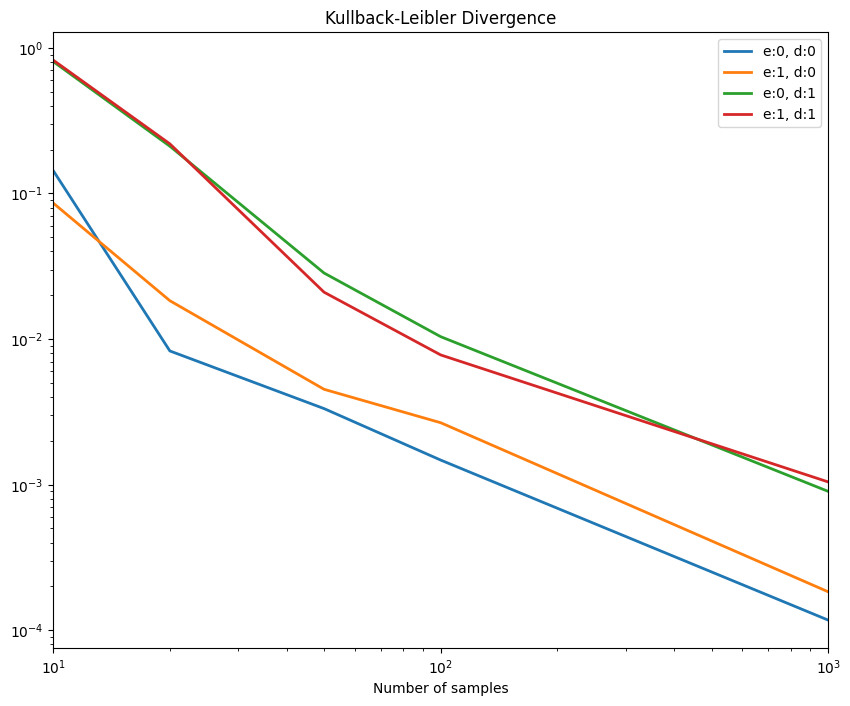

In [11]:
if __name__ == "__main__":
    from utils import approx_error
    
    np.random.seed(0)
    errs = {}
    sample_counts = np.array([10, 20, 50, 100, 1000])
    
    # compute approximation error
    for d, e in zip([0, 0, 1, 1], [0, 1, 0, 1]):
        errs[(d, e)] = approx_error(
            bayes_net,
            likelihood_weighting,  
            A_DE[:, d, e],
            _A_,
            {_D_:d, _E_:e}, 
            sample_counts,
            n_runs=100
        )
    
    # plot
    plt.figure(figsize=(10, 8))
    plt.title('Kullback-Leibler Divergence')
    for d, e in zip([0, 0, 1, 1], [0, 1, 0, 1]):
        plt.plot(sample_counts, errs[(d, e)], label=f'e:{e}, d:{d}', lw=2)
        
    plt.legend()
    plt.xscale('log')
    plt.yscale('log')
    plt.xlim(sample_counts.min(), sample_counts.max())
    plt.xlabel('Number of samples')
    plt.show()